# EDA: Default of Credit Card Clients

[Описание признаков и кодов UCI](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients).

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root / 'src'))
from credit_default.eda import EDAProcessor

df = pd.read_csv(root / 'data/processed/clients.csv')
target = 'default.payment.next.month'
categories = ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0']
eda = EDAProcessor(df, output_dir=root / 'reports/figures')
print(df.shape)

(30000, 25)


## Качество данных

In [2]:
summary = eda.generate_eda_summary()
display(summary['summary'])
print('Повторы ID:', df.ID.duplicated().sum())
print('Повторы строк:', summary['duplicate_count'])
print('Повторы без ID:', df.drop(columns='ID').duplicated().sum())
print('Повторы признаков:', df.drop(columns=['ID', target]).duplicated().sum())
print('Совпадающие столбцы:', summary['duplicate_columns'])

,Тип,Пропуски,"Пропуски, %",Уникальных
ID,int64,0,0.0,30000
LIMIT_BAL,int64,0,0.0,81
SEX,int64,0,0.0,2
EDUCATION,int64,0,0.0,7
MARRIAGE,int64,0,0.0,4
AGE,int64,0,0.0,56
PAY_0,int64,0,0.0,11
PAY_2,int64,0,0.0,11
PAY_3,int64,0,0.0,11
PAY_4,int64,0,0.0,11


Повторы ID: 0
Повторы строк: 0
Повторы без ID: 35
Повторы признаков: 56
Совпадающие столбцы: []


## Таргет

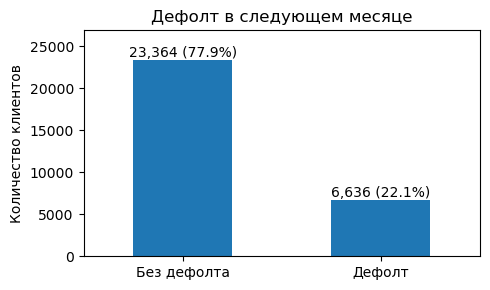

,Количество,"Доля, %"
default.payment.next.month,,
0,23364,77.88
1,6636,22.12


In [3]:
eda.plot_target_distribution(target)

Дефолт — 22,12%. Если всегда предсказывать 0, accuracy составит 77,88%. Поэтому оцениваем ROC-AUC, Precision, Recall и F1.

## Категории

Пол, образование и семейное положение — категории, записанные числами. PAY — статус погашения: положительные коды задают длительность задержки. На графиках — доля клиентов; подписи показывают количество и процент.

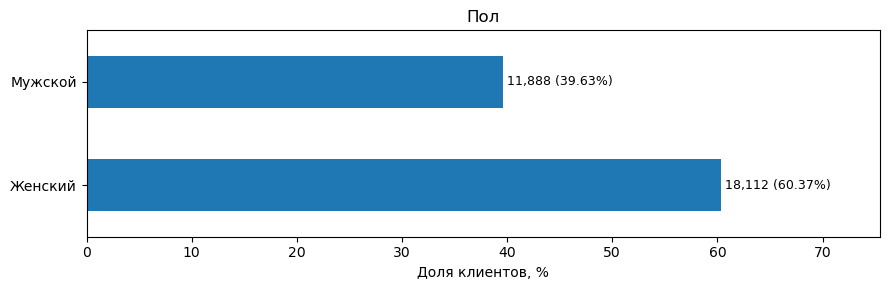

,Признак,Количество,"Доля, %"
Мужской,Пол,11888,39.63
Женский,Пол,18112,60.37


In [4]:
eda.plot_categorical_distributions(['SEX'])

Женщины — 60,37%, мужчины — 39,63%. Это состав выборки, а не сравнение риска дефолта.

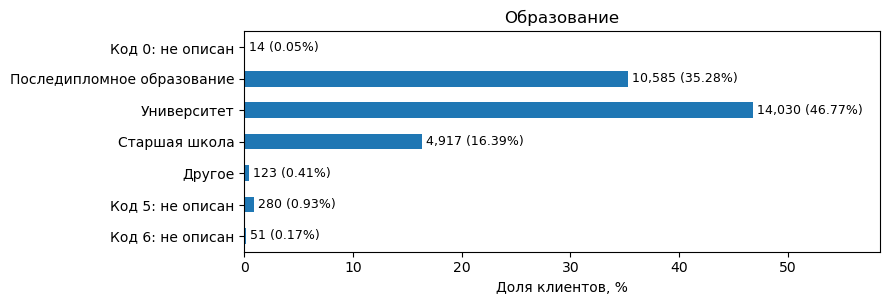

,Признак,Количество,"Доля, %"
Код 0: не описан,Образование,14,0.05
Последипломное образование,Образование,10585,35.28
Университет,Образование,14030,46.77
Старшая школа,Образование,4917,16.39
Другое,Образование,123,0.41
Код 5: не описан,Образование,280,0.93
Код 6: не описан,Образование,51,0.17


In [5]:
eda.plot_categorical_distributions(['EDUCATION'])

Университет — 46,77%, последипломное образование — 35,28%, старшая школа — 16,39%. Коды 0, 5 и 6 не расшифрованы в UCI.

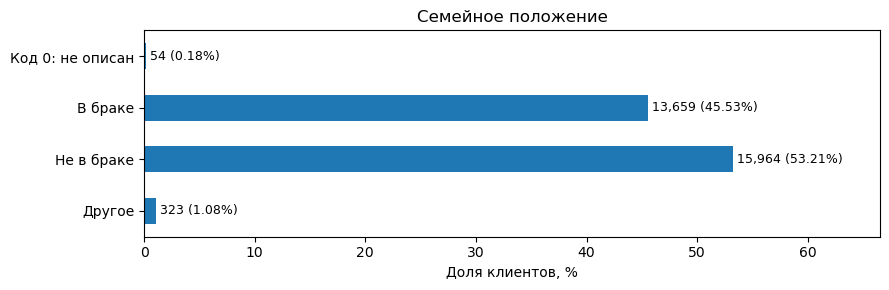

,Признак,Количество,"Доля, %"
Код 0: не описан,Семейное положение,54,0.18
В браке,Семейное положение,13659,45.53
Не в браке,Семейное положение,15964,53.21
Другое,Семейное положение,323,1.08


In [6]:
eda.plot_categorical_distributions(['MARRIAGE'])

Не в браке — 53,21%, в браке — 45,53%. Код 0 не расшифрован.

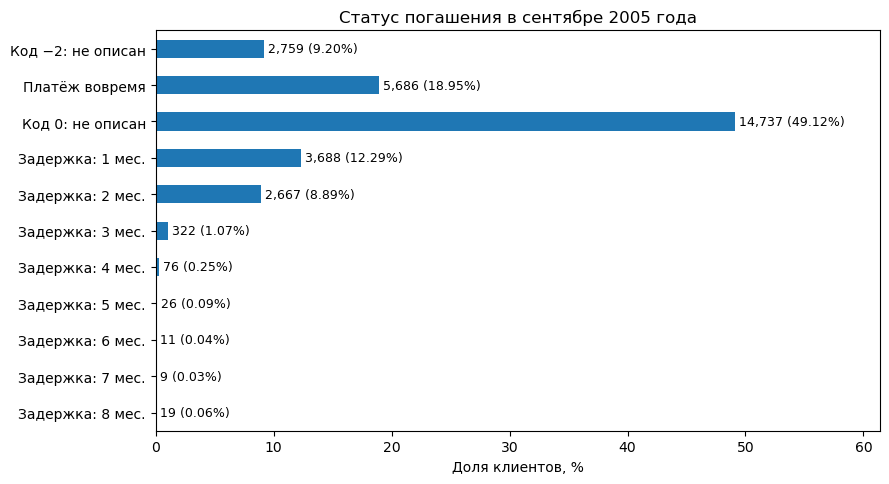

,Признак,Количество,"Доля, %"
Код −2: не описан,Статус погашения в сентябре 2005 года,2759,9.20
Платёж вовремя,Статус погашения в сентябре 2005 года,5686,18.95
Код 0: не описан,Статус погашения в сентябре 2005 года,14737,49.12
Задержка: 1 мес.,Статус погашения в сентябре 2005 года,3688,12.29
Задержка: 2 мес.,Статус погашения в сентябре 2005 года,2667,8.89
Задержка: 3 мес.,Статус погашения в сентябре 2005 года,322,1.07
Задержка: 4 мес.,Статус погашения в сентябре 2005 года,76,0.25
Задержка: 5 мес.,Статус погашения в сентябре 2005 года,26,0.09
Задержка: 6 мес.,Статус погашения в сентябре 2005 года,11,0.04
Задержка: 7 мес.,Статус погашения в сентябре 2005 года,9,0.03


In [7]:
eda.plot_categorical_distributions(['PAY_0'])

PAY_0 — статус погашения, не сумма платежа. Код −1 означает платёж вовремя, положительный код — месяцы задержки. Значения −2 и 0 в карточке UCI не объяснены; вместе они занимают большую часть выборки.

### Статусы погашения за шесть месяцев

Таблица показывает доли кодов в процентах. Сентябрь — PAY_0, август — PAY_2, далее до апреля — PAY_6. Отсутствующий PAY_1 — особенность названий исходного файла.

In [8]:
pay_columns = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
months = ['Сентябрь', 'Август', 'Июль', 'Июнь', 'Май', 'Апрель']
from credit_default.eda import LABELS
pay_shares = pd.DataFrame({
    month: df[col].value_counts(normalize=True) * 100
    for col, month in zip(pay_columns, months)
}).fillna(0).sort_index()
pay_shares.index = [LABELS['PAY_0'].get(value, str(value)) for value in pay_shares.index]
display(pay_shares.round(2))

,Сентябрь,Август,Июль,Июнь,Май,Апрель
Код −2: не описан,9.20,12.61,13.62,14.49,15.15,16.32
Платёж вовремя,18.95,20.17,19.79,18.96,18.46,19.13
Код 0: не описан,49.12,52.43,52.55,54.85,56.49,54.29
Задержка: 1 мес.,12.29,0.09,0.01,0.01,0.00,0.00
Задержка: 2 мес.,8.89,13.09,12.73,10.53,8.75,9.22
Задержка: 3 мес.,1.07,1.09,0.80,0.60,0.59,0.61
Задержка: 4 мес.,0.25,0.33,0.25,0.23,0.28,0.16
Задержка: 5 мес.,0.09,0.08,0.07,0.12,0.06,0.04
Задержка: 6 мес.,0.04,0.04,0.08,0.02,0.01,0.06
Задержка: 7 мес.,0.03,0.07,0.09,0.19,0.19,0.15


### Редкие категории

Здесь редкие — менее 5% строк. Это порог для просмотра, не правило удаления.

In [9]:
eda.find_rare_categories(categories, threshold=0.05)

{'Пол': [],
 'Образование': ['Код 5: не описан',
  'Другое',
  'Код 6: не описан',
  'Код 0: не описан'],
 'Семейное положение': ['Другое', 'Код 0: не описан'],
 'Статус погашения в сентябре 2005 года': ['Задержка: 3 мес.',
  'Задержка: 4 мес.',
  'Задержка: 5 мес.',
  'Задержка: 8 мес.',
  'Задержка: 6 мес.',
  'Задержка: 7 мес.']}

## Числовые признаки

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


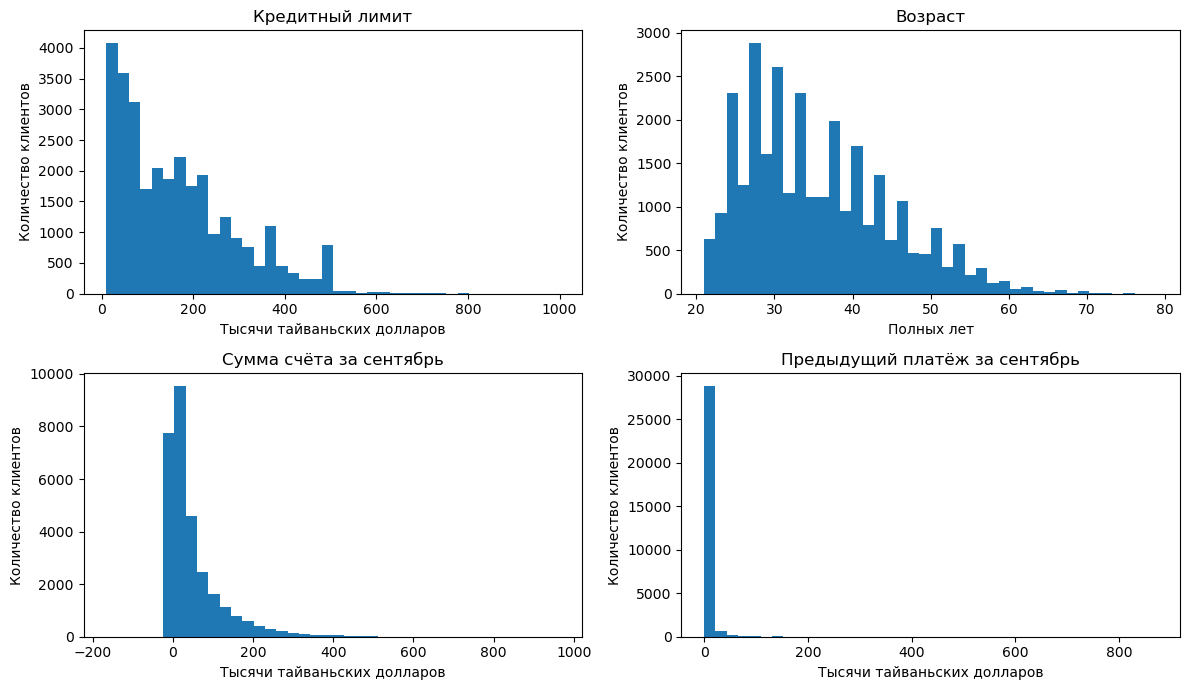

In [10]:
numeric = ['LIMIT_BAL', 'AGE'] + [f'BILL_AMT{i}' for i in range(1, 7)] + [f'PAY_AMT{i}' for i in range(1, 7)]
display(df[numeric].describe().T)

plots = [
    ('LIMIT_BAL', 'Кредитный лимит', 'Тысячи тайваньских долларов'),
    ('AGE', 'Возраст', 'Полных лет'),
    ('BILL_AMT1', 'Сумма счёта за сентябрь', 'Тысячи тайваньских долларов'),
    ('PAY_AMT1', 'Предыдущий платёж за сентябрь', 'Тысячи тайваньских долларов'),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (column, title, unit) in zip(axes.flat, plots):
    values = df[column] if column == 'AGE' else df[column] / 1000
    ax.hist(values, bins=40)
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.set_ylabel('Количество клиентов')
fig.tight_layout()
fig.savefig(root / 'reports/figures/numeric_distributions.png', dpi=120)
plt.show()


## Корреляции

Красный — положительная связь, синий — отрицательная, белый — около нуля. Диагональ равна 1: каждый признак сравнивается с собой. ID и категории исключены. Месяц 1 — сентябрь 2005 года, месяц 6 — апрель.

Счета за соседние месяцы тесно связаны. Это нужно учитывать при интерпретации коэффициентов линейной модели. Корреляция не означает причинность.

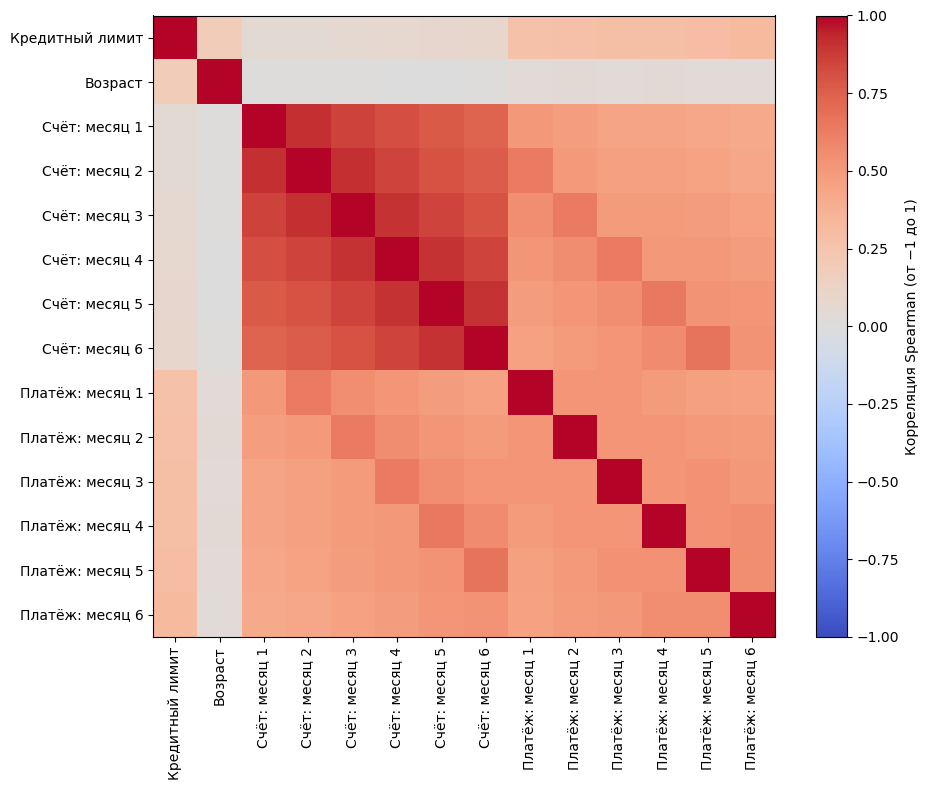

In [11]:
corr = df[numeric].corr(method='spearman')
names = ['Кредитный лимит', 'Возраст'] + [f'Счёт: месяц {i}' for i in range(1, 7)] + [f'Платёж: месяц {i}' for i in range(1, 7)]
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(numeric)), names, rotation=90)
ax.set_yticks(range(len(numeric)), names)
fig.colorbar(image, ax=ax, label='Корреляция Spearman (от −1 до 1)')
fig.tight_layout()
fig.savefig(root / 'reports/figures/correlations.png', dpi=120)
plt.show()

## Выводы

Пропусков и повторов ID нет. Без ID совпадают 35 строк; без ID и таргета — 56. Перед обучением проверим пересечение одинаковых наборов признаков между train и test.

Возраст — 21–79 лет, лимит — 10 тыс.–1 млн тайваньских долларов. Отрицательные счета есть, отрицательных платежей нет. У сумм длинный правый хвост. Редкие и большие значения автоматически не удаляем.

## Решения

- ID исключаем из признаков.
- EDUCATION=0/5/6, MARRIAGE=0 и PAY=-2/0 сохраняем: их смысл в карточке UCI не указан.
- PAY допускаем от −2 до 9. Код 9 описан в UCI, но в файле не встречается.
- Отрицательные BILL_AMT сохраняем; отрицательные PAY_AMT отклоняем.
- Возраст 18–100 и положительный лимит — правила проекта. Верхнюю границу сумм не задаём.
- Связь с таргетом и подбор признаков изучаем на train после разделения.

<a id="split"></a>

## Разделение и анализ train

Гипотезы проверяем на train. Test оставляем для итоговой оценки.

Данные содержат один срез клиентов. Временное разделение невозможно, порядок ID неизвестен. Одинаковые профили оставляем вместе, чтобы избежать пересечения выборок. Проверка на будущих месяцах здесь недоступна.

In [ ]:
import json
import numpy as np
from matplotlib.ticker import PercentFormatter
from IPython.display import display

from credit_default.data import TARGET, PAY, BILLS, PAYMENTS
from credit_default.eda import LABELS, TITLES
from credit_default.features import add_features

train = pd.read_csv(root / 'data/processed/train.csv')
figures = root / 'reports/figures/train'
figures.mkdir(parents=True, exist_ok=True)
base_rate = train[TARGET].mean()
print(f'Train: {len(train):,} клиентов. Дефолт: {base_rate:.2%}.')

### Разделение данных

Группируем одинаковые признаки без ID и цели. `StratifiedGroupKFold`, seed=42: один блок из пяти отдаём в test, остальные в train. Размер test около 20%, группы не разрываем.

Разные ответы внутри профиля сохраняем. Состав выборок записан в `reports/split_ids.csv`.

In [ ]:
split = json.loads((root / 'reports/split_summary.json').read_text())
display(pd.Series(split).to_frame('Значение'))

### Доля дефолта по категориям

Столбцы показывают долю дефолта, пунктир показывает среднее по train. `n` обозначает размер группы. Звёздочкой отмечены малые группы. Связь признака с дефолтом не доказывает причину.

In [ ]:
def category_report(column):
    table = train.groupby(column)[TARGET].agg(['size', 'sum', 'mean'])
    table.columns = ['Клиентов', 'Дефолтов', 'Доля дефолта']
    labels = LABELS.get(column, LABELS['PAY_0'] if column in PAY else {})
    table.index = [labels.get(value, str(value)) for value in table.index]
    title = TITLES.get(column, column)
    fig, ax = plt.subplots(figsize=(10, max(3, len(table) * 0.45)))
    table['Доля дефолта'].plot.barh(ax=ax, color='#477aa5')
    ax.invert_yaxis()
    ax.axvline(base_rate, color='#a14d38', linestyle='--', label=f'Среднее: {base_rate:.1%}')
    ax.set_xlim(0, 1.3)
    ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Доля дефолта внутри категории')
    ax.set_ylabel('')
    ax.set_title(title)
    for bar, (_, row) in zip(ax.patches, table.iterrows()):
        mark = '*' if row['Клиентов'] < 100 else ''
        ax.text(row['Доля дефолта'] + 0.01, bar.get_y() + bar.get_height() / 2,
                f"{row['Доля дефолта']:.1%}; n={int(row['Клиентов']):,}{mark}", va='center', fontsize=9, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.85})
    ax.legend(loc='lower right')
    fig.tight_layout()
    fig.savefig(figures / f'default_by_{column}.png', dpi=120)
    plt.show()
    plt.close(fig)
    table.to_csv(root / 'reports' / f'train_default_by_{column}.csv')
    return table.round(4)

In [ ]:
category_report('SEX')

В train дефолт у 24,28% мужчин и 20,51% женщин.

In [ ]:
category_report('EDUCATION')

В крупных группах образования дефолт у 19,00–25,01% клиентов. У кода 0 всего 11 клиентов, поэтому нулевая доля ненадёжна.

In [ ]:
category_report('MARRIAGE')

Дефолт у 23,43% клиентов в браке и 20,76% клиентов вне брака. Разница меньше, чем между группами задержек.

In [ ]:
category_report('PAY_0')

При задержке на месяц дефолт у 34,49%, на два месяца у 68,58%. В группах с задержкой 4–8 месяцев менее 100 клиентов, поэтому проценты нестабильны.

#### История задержек

Сравниваем задержку от двух месяцев с остальными кодами. Показываем размер групп и долю дефолта. Коды −2 и 0 не считаем длительностью задержки.

In [ ]:
history = []
for column, month in zip(PAY, ['Сентябрь', 'Август', 'Июль', 'Июнь', 'Май', 'Апрель']):
    delayed = train[column] >= 2
    for flag, label in [(False, 'Остальные коды'), (True, 'Задержка ≥ 2 мес.')]:
        part = train.loc[delayed == flag, TARGET]
        history.append({'Месяц': month, 'Группа': label,
                        'Клиентов': len(part), 'Дефолт, %': part.mean() * 100})
history = pd.DataFrame(history)
display(history.round(2))
history.to_csv(root / 'reports/train_delay_history.csv', index=False)
ax = history.pivot(index='Месяц', columns='Группа', values='Дефолт, %').reindex(
    ['Сентябрь', 'Август', 'Июль', 'Июнь', 'Май', 'Апрель']
).plot.bar(figsize=(10, 4), rot=0)
ax.set_ylabel('Доля дефолта, %')
ax.set_xlabel('Месяц 2005 года')
ax.set_title('Дефолт и длительная задержка платежа')
ax.figure.tight_layout()
ax.figure.savefig(figures / 'delay_history.png', dpi=120)
plt.show()
plt.close(ax.figure)

### Числовые признаки по классам

Частоты считаем внутри каждого класса. Суммы указаны в тысячах тайваньских долларов. Ось ограничена p99 train, данные выше границы сохраняем.

In [ ]:
plots = [
    ('AGE', 'Возраст', 'Полных лет'),
    ('LIMIT_BAL', 'Кредитный лимит', 'Тысячи тайваньских долларов'),
    ('BILL_AMT1', 'Счёт за сентябрь', 'Тысячи тайваньских долларов'),
    ('PAY_AMT1', 'Платёж за сентябрь', 'Тысячи тайваньских долларов'),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (column, title, unit) in zip(axes.flat, plots):
    values = train[column] if column == 'AGE' else train[column] / 1000
    upper = values.max() if column == 'AGE' else values.quantile(0.99)
    bins = np.linspace(values.min(), upper, 31)
    for label, name, color in [(0, 'Без дефолта', '#477aa5'), (1, 'Дефолт', '#b75b43')]:
        part = values[train[TARGET] == label]
        ax.hist(part, bins=bins, weights=np.ones(len(part)) * 100 / len(part),
                histtype='step', linewidth=2, label=name, color=color)
    ax.set_title(title)
    ax.set_xlabel(unit)
    ax.set_ylabel('Доля внутри класса, %')
    ax.legend()
fig.tight_layout()
fig.savefig(figures / 'numeric_by_target.png', dpi=120)
plt.show()
plt.close(fig)

medians = train.groupby(TARGET)[['AGE', 'LIMIT_BAL'] + BILLS + PAYMENTS].median().T
medians.columns = ['Без дефолта: медиана', 'Дефолт: медиана']
display(medians)
medians.to_csv(root / 'reports/train_medians_by_target.csv')

Медиана возраста в обоих классах 34 года. Медиана лимита у клиентов с дефолтом 90 тыс., без дефолта 150 тыс. Распределения счетов сильно перекрываются.

### Нули, отрицательные суммы и крайние значения

Перцентили считаем на train. Значения выше p99 автоматически не удаляем.

In [ ]:
amounts = train[BILLS + PAYMENTS + ['LIMIT_BAL']]
amount_summary = pd.DataFrame({
    'Нулей': amounts.eq(0).sum(),
    'Отрицательных': amounts.lt(0).sum(),
    'Минимум': amounts.min(),
    'Медиана': amounts.median(),
    'p99': amounts.quantile(0.99),
    'Максимум': amounts.max(),
    'Выше p99': amounts.gt(amounts.quantile(0.99)).sum(),
})
display(amount_summary.round(2))
amount_summary.to_csv(root / 'reports/train_amounts.csv')

special = []
for column, flag, name in [
    ('PAY_AMT1', train.PAY_AMT1.eq(0), 'Нулевой платёж за сентябрь'),
    ('BILL_AMT1', train.BILL_AMT1.lt(0), 'Отрицательный счёт за сентябрь'),
]:
    for value in [False, True]:
        part = train.loc[flag == value, TARGET]
        special.append({'Признак': name, 'Условие выполнено': value,
                        'Клиентов': len(part), 'Дефолт, %': part.mean() * 100})
display(pd.DataFrame(special).round(2))

<a id="hypotheses"></a>

## Проверка гипотез

Проверяем возраст, образование, семейное положение и историю платежей на train.

### Взгляд банка и клиента

| Вопрос | Что есть | Чего нет |
|---|---|---|
| Есть ли деньги на платёж? | Счета, платежи, лимит | Доход, расходы, занятость, другие долги |
| Это разовая задержка или повторяющаяся? | Шесть статусов платежей | Причина задержки, точная дата платежа |
| Насколько велика нагрузка? | Счёт относительно лимита | Обязательный минимум, общая сумма обязательств |
| Имеет ли значение жизненный этап? | Возраст, образование, семейное положение | Иждивенцы, семейный доход, совместный бюджет |
| Отличается ли регион? | Только общий контекст: Тайвань | Регион, город, адрес |

Доход, иждивенцы и регион неизвестны. Выводы относятся к держателям карт, а не ко всем заявителям.

In [ ]:
df = add_features(train)
figures = root / 'reports/figures/hypotheses'
figures.mkdir(parents=True, exist_ok=True)

# Не смешиваем неизвестные коды с подтверждённым погашением вовремя.
df['LATEST_STATUS'] = df.PAY_0.map({-2: 'Код −2', -1: 'Вовремя', 0: 'Код 0', 1: 'Задержка 1 мес.'}).fillna('Задержка ≥2 мес.')
df['PREVIOUS_DELAYS'] = pd.cut(df.previous_delay_months, [-1, 0, 1, 3, 5], labels=['0', '1', '2–3', '4–5'])
df['LIMIT_GROUP'] = pd.cut(df.LIMIT_BAL, [0, 50000, 150000, 300000, np.inf], labels=['≤50 тыс.', '50–150 тыс.', '150–300 тыс.', '>300 тыс.'])
df['BILL_RATIO_GROUP'] = pd.cut(df.bill_to_limit, [-np.inf, 0, 0.3, 0.6, 1, np.inf], labels=['≤0', '0–30%', '30–60%', '60–100%', '>100%'])
df['MARRIAGE_LABEL'] = df.MARRIAGE.map(LABELS['MARRIAGE'])
df['EDUCATION_LABEL'] = df.EDUCATION.map(LABELS['EDUCATION'])
print(f'Train: {len(df):,} клиентов, дефолт {df[TARGET].mean():.2%}.')


def risk_table(columns):
    table = df.groupby(columns, observed=True, dropna=False)[TARGET].agg(['size', 'sum', 'mean'])
    table.columns = ['Клиентов', 'Дефолтов', 'Дефолт, %']
    table['Дефолт, %'] *= 100
    table['Малая группа'] = table['Клиентов'] < 100
    return table.round(2)


def risk_heatmap(row, column, title, filename):
    table = risk_table([row, column]).reset_index()
    rates = table.pivot(index=row, columns=column, values='Дефолт, %')
    counts = table.pivot(index=row, columns=column, values='Клиентов').reindex_like(rates)
    fig, ax = plt.subplots(figsize=(11, max(4, len(rates) * 0.6)))
    visible = rates.where(counts >= 100)
    cmap = plt.get_cmap('YlOrRd').copy()
    cmap.set_bad('#eeeeee')
    image = ax.imshow(visible, vmin=0, vmax=100, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(rates.columns)), rates.columns, rotation=20, ha='right')
    ax.set_yticks(range(len(rates.index)), rates.index)
    for i in range(len(rates)):
        for j in range(len(rates.columns)):
            count = counts.iloc[i, j]
            if pd.isna(count):
                text = 'Нет данных'
            elif count < 100:
                text = f'n={int(count)}*'
            else:
                text = f'{rates.iloc[i, j]:.1f}%\nn={int(count):,}'
            ax.text(j, i, text, ha='center', va='center', fontsize=9)
    ax.set_title(title + '\nСерые ячейки: менее 100 клиентов')
    fig.colorbar(image, ax=ax, label='Доля дефолта, %')
    fig.tight_layout()
    fig.savefig(figures / filename, dpi=120)
    plt.show()
    plt.close(fig)
    table.to_csv(root / 'reports' / filename.replace('.png', '.csv'), index=False)
    return table
df['BILL_CHANGE_GROUP'] = pd.cut(df.bill_change_to_limit * 100, [-np.inf, -25, 0, 25, np.inf], labels=['≤−25 п.п.', '−25–0 п.п.', '0–25 п.п.', '>25 п.п.'])
df['PAYMENT_CHANGE_GROUP'] = pd.cut(df.payment_change_to_limit * 100, [-np.inf, -5, 0, 5, np.inf], labels=['≤−5 п.п.', '−5–0 п.п.', '0–5 п.п.', '>5 п.п.'])

### 1. Возраст, семья и образование

Различия между группами могут зависеть от истории задержек и лимита. Сравниваем семейное положение внутри возрастов, образование внутри статусов погашения. Группы менее 100 клиентов отмечаем как малые.

In [ ]:
display(risk_table(['AGE_BAND']))
risk_heatmap('AGE_BAND', 'LATEST_STATUS', 'Возраст при сопоставимом последнем статусе', 'age_by_status.png')

In [ ]:
risk_heatmap('AGE_BAND', 'MARRIAGE_LABEL', 'Семейное положение внутри возрастных групп', 'age_by_marriage.png')

In [ ]:
risk_heatmap('EDUCATION_LABEL', 'LATEST_STATUS', 'Образование при сопоставимом последнем статусе', 'education_by_status.png')

#### Сравнение при одинаковом составе групп

Приводим группы к общему составу по возрасту и последнему статусу. Оставляем сочетания, где в каждой группе есть хотя бы 100 клиентов. Показываем долю оставшегося train. Поправка учитывает только два признака и не доказывает причинность.

In [ ]:
def standardized_rates(column, values):
    part = df[df[column].isin(values)]
    counts = part.groupby(['AGE_BAND', 'LATEST_STATUS', column], observed=True).size().unstack(column)
    shared = counts.reindex(columns=values).fillna(0).ge(100).all(axis=1)
    strata = counts.index[shared]
    if len(strata) == 0:
        return pd.DataFrame(), 0.0
    pairs = pd.MultiIndex.from_frame(part[['AGE_BAND', 'LATEST_STATUS']])
    common = part.loc[pairs.isin(strata)]
    weights = common.groupby(['AGE_BAND', 'LATEST_STATUS'], observed=True).size()
    weights = weights / weights.sum()
    result = []
    for value in values:
        group = part[part[column] == value]
        rates = group.groupby(['AGE_BAND', 'LATEST_STATUS'], observed=True)[TARGET].mean()
        result.append({'Группа': value, 'Клиентов': len(group),
                       'Исходная доля, %': group[TARGET].mean() * 100,
                       'Клиентов в общих стратах': int((common[column] == value).sum()),
                       'Доля в общих стратах, %': common.loc[common[column] == value, TARGET].mean() * 100,
                       'Стандартизованная доля, %': rates.reindex(weights.index).mul(weights).sum() * 100})
    return pd.DataFrame(result).round(2), len(common) / len(df)

for column, values in [('SEX', [1, 2]), ('MARRIAGE', [1, 2]), ('EDUCATION', [1, 2, 3])]:
    table, coverage = standardized_rates(column, values)
    print(f'{column}: общие страты охватывают {coverage:.1%} train')
    display(table)
    table.to_csv(root / 'reports' / f'adjusted_{column}.csv', index=False)

После поправки доли дефолта для образования 2 и 3 близки: 23,75% и 23,63%. Для образования 1 получаем 20,46%. В браке 22,71%, вне брака 20,86%. Сравнение ограничено общими группами; доход и другие долги неизвестны.

### 2. Лимит и нагрузка

Сравниваем лимиты при одинаковом последнем статусе. Высокий лимит может отражать отбор банка.

Счёт относительно лимита описывает нагрузку на карту, а не отношение долга к доходу. Значения выше 100% сохраняем: история лимита неизвестна.

In [ ]:
risk_heatmap('LIMIT_GROUP', 'LATEST_STATUS', 'Лимит при сопоставимом последнем статусе', 'limit_by_status.png')

In [ ]:
risk_heatmap('BILL_RATIO_GROUP', 'LATEST_STATUS', 'Счёт относительно лимита и статус погашения', 'bill_ratio_by_status.png')

#### Изменение сумм

Сравниваем счёт в апреле и сентябре, средний платёж за последние и предыдущие три месяца. Изменения делим на лимит. Ось показывает процентные пункты от лимита, а не темп роста суммы.

In [ ]:
risk_heatmap('BILL_CHANGE_GROUP', 'LATEST_STATUS', 'Изменение счёта относительно лимита', 'bill_change_by_status.png')

In [ ]:
risk_heatmap('PAYMENT_CHANGE_GROUP', 'LATEST_STATUS', 'Изменение платежей относительно лимита', 'payment_change_by_status.png')

При последней задержке от двух месяцев дефолт у 67,75–71,07% клиентов во всех группах лимита. При статусе «вовремя» получаем 25,38% для лимита до 50 тыс. и 9,34% для лимита выше 300 тыс. Лимит рассматриваем вместе с историей. Польза его повышения не доказана.

### 3. Разовая и повторяющаяся задержка

При одинаковом последнем статусе сравниваем число прошлых задержек. Учитываем положительные коды. Коды −2 и 0 не считаем оплатой вовремя.

In [ ]:
risk_heatmap('PREVIOUS_DELAYS', 'LATEST_STATUS', 'Предыдущие задержки при одинаковом последнем статусе', 'history_by_status.png')

При последнем статусе «вовремя» дефолт у 13,44% клиентов без прошлых задержек, 28,32% с одной и 38,46% с двумя или тремя. История добавляет информацию. В группе с четырьмя или пятью задержками всего 43 клиента.

### 4. Нулевой платёж

Сравниваем нулевой сентябрьский платёж при положительном и неположительном августовском счёте. Затем учитываем последний статус. Срок обязательного платежа неизвестен, поэтому факт неисполнения обязательства не устанавливаем.

In [ ]:
df['ZERO_PAYMENT'] = df.PAY_AMT1.eq(0).map({True: 'Нулевой платёж', False: 'Положительный платёж'})
df['PREVIOUS_BILL'] = df.BILL_AMT2.gt(0).map({True: 'Августовский счёт >0', False: 'Августовский счёт ≤0'})
display(risk_table(['PREVIOUS_BILL', 'ZERO_PAYMENT']))
display(risk_table(['PREVIOUS_BILL', 'ZERO_PAYMENT', 'LATEST_STATUS']))

При нулевом платеже и положительном счёте дефолт у 52,99% клиентов (1 757 человек). При неположительном счёте получаем 24,04% (2 446). Нулевой платёж рассматриваем вместе со счётом и статусом задержки.

### 5. Польза признаков для прогноза

Сравниваем семь наборов на пяти одинаковых групповых блоках train. Импутация, масштабирование и кодирование обучаются внутри блока. Производные признаки используют только свою строку.

Используем LogisticRegression, C=1, без подбора параметров. Проверка показывает пользу признаков для линейной модели.

ROC-AUC оценивает порядок клиентов по риску: 0,5 соответствует случайному ранжированию, 1 соответствует идеальному. При AUC 0,79 клиент с дефолтом получает больший риск примерно в 79% пар с клиентом без дефолта. Это не доля верных ответов.

ROC-AUC и AP лучше при больших значениях, Brier при меньших. Ориентир AP равен доле дефолта. `std` показывает разброс по блокам. Итоговую оценку получим на test.

In [ ]:
scores = pd.read_csv(root / 'reports/hypothesis_cv_folds.csv')
summary = scores.groupby('Вариант', sort=False)[['ROC-AUC', 'AP', 'Brier']].agg(['mean', 'std'])
display(summary.round(4))
paired = scores.pivot(index='Блок', columns='Вариант', values='ROC-AUC')
delta = pd.DataFrame({
    'История сверх последнего статуса': paired['Шесть статусов'] - paired['Последний статус'],
    'Демография сверх поведения': paired['Поведение + демография'] - paired['Поведение'],
    'Новые признаки сверх поведения': paired['Поведение + новые признаки'] - paired['Поведение'],
    'Демография сверх расширенного поведения': paired['Все признаки'] - paired['Поведение + новые признаки'],
})
display(delta.round(4))
delta.to_csv(root / 'reports/hypothesis_auc_deltas.csv')
fig, ax = plt.subplots(figsize=(10, 5))
summary[('ROC-AUC', 'mean')].plot.barh(ax=ax, xerr=summary[('ROC-AUC', 'std')], color='#477aa5')
ax.set_xlim(0.45, 0.9)
ax.set_xlabel('ROC-AUC: среднее ± стандартное отклонение по блокам train')
ax.set_title('Какие признаки добавляют информацию')
fig.tight_layout()
fig.savefig(figures / 'cv_feature_sets.png', dpi=120)
plt.show()
plt.close(fig)

#### Проверка на деревьях

Повторяем сравнение с HistGradientBoostingClassifier на тех же пяти блоках. Параметры фиксированы, настройки и хеш train сохранены в JSON.

In [ ]:
boosting = pd.read_csv(root / 'reports/hypothesis_boosting_cv_folds.csv')
display(boosting.groupby('Вариант', sort=False)[['ROC-AUC', 'AP', 'Brier']].agg(['mean', 'std']).round(4))
boosting_paired = boosting.pivot(index='Блок', columns='Вариант', values='ROC-AUC')
display(pd.DataFrame({
    'Новые признаки сверх поведения': boosting_paired['Поведение + новые признаки'] - boosting_paired['Поведение'],
    'Демография сверх расширенного поведения': boosting_paired['Все признаки'] - boosting_paired['Поведение + новые признаки'],
}).round(4))

Шесть статусов вместо одного повышают ROC-AUC линейной модели с 0,714 до 0,748. Демография отдельно даёт 0,564. Производные признаки повышают AUC с 0,768 до 0,775 у линейной модели и с 0,782 до 0,785 у деревьев. Все признаки у деревьев дают AUC 0,788 и AP 0,563. Демография сверх расширенного поведения добавляет около 0,002 AUC. Результаты относятся к CV на train.

<a id="conclusions"></a>

## Выводы для модели

* Используем историю всех шести месяцев.
* Сравниваем демографию с учётом задержек.
* Рассматриваем счета и платежи вместе с лимитом.
* Исключаем ID. Сохраняем неизвестные коды, редкие категории и крайние суммы.

Выбор модели описан в [02_experiments.ipynb](02_experiments.ipynb).